# Predicting Customer Churn in Telecommunications Using Supervised Machine Learning

## 1. Introduction

Customer churn represents the termination of a customer's relationship with a telecommunications provider. Accurate identification of customers at risk of leaving may support retention planning and resource allocation. 
I have decided to look at this topic as I am currently in a house share, where my housemates and I have recently started considering factors like contracts and renewals. This sparked my interest to see if findings from this analysis are something my housemates and I can relate to why people decide to stay with a current contract or switch.

The task is formulated as binary classification, with `Churn` as the target variable. Logistic Regression and Random Forest are selected for comparison. Logistic Regression provides a linear baseline, while Random Forest can model non-linear relationships and feature interactions.

### Dataset

The IBM Telco Customer Churn dataset contains 7,043 customer records and demographic, account and service variables. The target variable, `Churn`, identifies whether a customer left the provider. `customerID` is excluded because it is an identifier rather than a predictive customer characteristic.

Data source: IBM sample Telco Customer Churn dataset, distributed through Kaggle ([Kaggle, n.d.](#ref-ibm)). The dataset describes a single provider and may not represent the wider telecommunications market.


## 2. Data loading and inspection

The dataset is loaded from the CSV file supplied with the notebook. The code verifies the file path and required target column. Blank entries in `TotalCharges` are converted to missing values; imputation is conducted after the train-test split within the modelling pipelines.


In [4]:
# 2.1 Imports and reproducibility
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
DATA_PATH = Path("Telco_Customer_Churn.csv")
sns.set_theme(style="whitegrid", context="notebook")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Put the CSV in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH)
required_columns = {"Churn", "customerID", "TotalCharges", "Contract"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing expected columns: {sorted(missing_columns)}")

# Convert blank TotalCharges entries to NaN; do not calculate an imputation value here.
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True),
    errors="coerce"
)

print(f"Dataset dimensions: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Duplicate rows: {df.duplicated().sum():,}")
print("\nData types and non-null counts:")
df.info()
display(df.head())

Dataset dimensions: 7,043 rows × 21 columns
Duplicate rows: 0

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Data-quality assessment

The following checks examine target labels, missing observations and duplicate records. Missing values in `TotalCharges` are retained at this stage and handled using training-data statistics during model fitting.

In [5]:
# 2.2 Data quality checks
print("Target values:")
print(df["Churn"].value_counts(dropna=False))

print("\nMissing values by column (largest first):")
missing_summary = df.isna().sum().loc[lambda x: x.gt(0)].sort_values(ascending=False)
display(missing_summary.to_frame("missing_count"))

print(f"\nMissing TotalCharges values: {df['TotalCharges'].isna().sum()}")
print(f"Duplicate customer IDs: {df['customerID'].duplicated().sum()}")

if not set(df["Churn"].dropna().unique()).issubset({"Yes", "No"}):
    raise ValueError("Unexpected values found in Churn; inspect target labels before modelling.")

Target values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Missing values by column (largest first):


,missing_count
TotalCharges,11



Missing TotalCharges values: 11
Duplicate customer IDs: 0


## 3. Exploratory data analysis

Figure 1 presents the target-class distribution and observed churn rates by contract type. These summaries describe class balance and variation between contract groups. The results are descriptive and do not establish causal relationships.


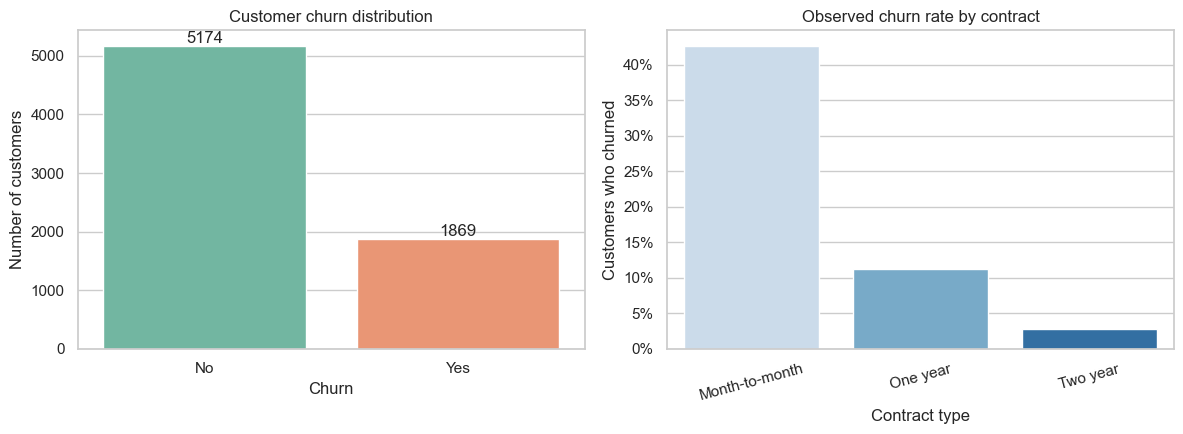

Overall churn rate: 26.5%


,churn_rate
Contract,
Month-to-month,0.427097
One year,0.112695
Two year,0.028319


In [6]:
# Figure 1: target distribution and descriptive churn rate by contract
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"])
sns.barplot(
    x=churn_counts.index, y=churn_counts.values,
    hue=churn_counts.index, legend=False, ax=axes[0], palette="Set2"
)
axes[0].set(title="Customer churn distribution", xlabel="Churn", ylabel="Number of customers")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f")

contract_churn = (
    df.groupby("Contract", observed=False)["Churn"]
      .apply(lambda values: (values == "Yes").mean())
      .sort_values(ascending=False)
)
sns.barplot(
    x=contract_churn.index, y=contract_churn.values,
    hue=contract_churn.index, legend=False, ax=axes[1], palette="Blues"
)
axes[1].set(
    title="Observed churn rate by contract",
    xlabel="Contract type", ylabel="Customers who churned"
)
axes[1].tick_params(axis="x", rotation=15)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))

plt.tight_layout()
plt.show()

print("Overall churn rate: {:.1%}".format((df["Churn"] == "Yes").mean()))
display(contract_churn.rename("churn_rate").to_frame())

**Figure 1.** The left figure displays the distribution of churn outcomes. The right figure compares observed churn rates across contract types. The class distribution indicates whether evaluation measures beyond accuracy are required. Differences between contract groups are descriptive associations.


## 4. Data partitioning and preprocessing

The data is divided into stratified training and test sets before preprocessing. Stratification preserves the target-class proportions across both partitions. The test set is reserved for final model evaluation.

Imputation and categorical encoding are implemented within scikit-learn pipelines. Numerical variables are median-imputed; categorical variables are imputed using the most frequent training value and one-hot encoded. Numerical features are scaled for Logistic Regression. During cross-validation, preprocessing is fitted independently within each training fold, reducing the risk of data leakage. Scikit-learn pipelines allow data transformations and model fitting to be combined into a single workflow ([Scikit-learn developers, n.d.-b](#ref-sklearn-pipeline)).


In [7]:
# 4.1 Separate predictors and target, then split raw data
model_df = df.drop(columns=["customerID"]).copy()
X = model_df.drop(columns=["Churn"])
y = model_df["Churn"].map({"No": 0, "Yes": 1}).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print(f"Training observations: {len(X_train):,}")
print(f"Test observations: {len(X_test):,}")
print(f"Numeric predictors ({len(numeric_features)}): {numeric_features}")
print(f"Categorical predictors ({len(categorical_features)}): {categorical_features}")
print(f"Training churn rate: {y_train.mean():.1%}")
print(f"Test churn rate: {y_test.mean():.1%}")

def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

Training observations: 5,634
Test observations: 1,409
Numeric predictors (4): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical predictors (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Training churn rate: 26.5%
Test churn rate: 26.5%


## 5. Model fitting and hyperparameter selection

Both classifiers are fitted using the same training partition. Logistic Regression is used as the baseline model, with regularisation parameter `C` selected by stratified cross-validation. Random Forest is tuned over the number of trees, maximum tree depth and minimum samples required for a split. Logistic Regression is used as a baseline classification method, while Random Forest provides a tree-based ensemble approach ([Scikit-learn developers, n.d.-d](#ref-sklearn-logistic); [Scikit-learn developers, n.d.-e](#ref-sklearn-forest)).

The searches maximise mean cross-validated ROC-AUC. Hyperparameter selection is restricted to the training data; the held-out test set is used only for final evaluation. The parameter grids are limited to maintain a practical execution time on JupyterHub.


In [8]:
# 5.1 Logistic Regression pipeline and cross-validated tuning
lr_pipeline = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("scaler", StandardScaler(with_mean=False)),
    ("classifier", LogisticRegression(
        max_iter=2000, solver="liblinear", random_state=RANDOM_STATE
    ))
])

lr_grid = {"classifier__C": [0.1, 1.0, 10.0]}
lr_search = GridSearchCV(
    estimator=lr_pipeline, param_grid=lr_grid, scoring="roc_auc",
    cv=cv, n_jobs=-1, refit=True
)
lr_search.fit(X_train, y_train)

print("Logistic Regression best parameters:", lr_search.best_params_)
print(f"Logistic Regression mean CV ROC-AUC: {lr_search.best_score_:.4f}")

Logistic Regression best parameters: {'classifier__C': 10.0}
Logistic Regression mean CV ROC-AUC: 0.8461


In [9]:
# 5.2 Random Forest pipeline and cross-validated tuning
rf_pipeline = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("classifier", RandomForestClassifier(
        random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1
    ))
])

rf_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10],
    "classifier__min_samples_split": [2, 10]
}
rf_search = GridSearchCV(
    estimator=rf_pipeline, param_grid=rf_grid, scoring="roc_auc",
    cv=cv, n_jobs=-1, refit=True
)
rf_search.fit(X_train, y_train)

print("Random Forest best parameters:", rf_search.best_params_)
print(f"Random Forest mean CV ROC-AUC: {rf_search.best_score_:.4f}")

Random Forest best parameters: {'classifier__max_depth': 10, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 200}
Random Forest mean CV ROC-AUC: 0.8430


## 6. Model evaluation

The selected models are evaluated on the held-out test set using a classification threshold of 0.5. Performance is reported using accuracy, precision, recall, F1-score, ROC-AUC and average precision. The threshold provides a consistent basis for comparison; alternative thresholds are examined later.

Let `TP` denote true positives, `TN` true negatives, `FP` false positives and `FN` false negatives, with churn defined as the positive class.

**Recall**

$$\text{Recall} = \frac{\text{True Positive}}{\text{True Positive} + \text{False Negative}}$$

Recall is the proportion of actual churn cases correctly identified.

**Precision**

$$\text{Precision} = \frac{\text{True Positive}}{\text{True Positive} + \text{False Positive}}$$

Precision is the proportion of predicted churn cases that are actual churn cases.

**F1-score**

$$F_1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

The F1-score is the harmonic mean of precision and recall.

**Accuracy**

$$\text{Accuracy} = \frac{\text{True Positive} + \text{True Negative}}{\text{True Positive} + \text{True Negative} + \text{False Positive} + \text{False Negative}}$$

Accuracy is the proportion of all test observations classified correctly.

**ROC-AUC**

ROC-AUC is the area under the receiver operating characteristic curve and measures discrimination across classification thresholds. A value of 0.5 indicates no discriminatory ability beyond random ranking; a value of 1.0 indicates perfect discrimination.

**Average precision** summarises the precision-recall curve and provides a complementary measure when the positive class is less frequent[cite: 1].

The evaluation measures are calculated using the classification metrics provided by Scikit-learn ([Scikit-learn developers, n.d.-a](#ref-sklearn-guide)).


In [10]:
# 6.1 Predictions and probability estimates
models = {
    "Logistic Regression": lr_search.best_estimator_,
    "Tuned Random Forest": rf_search.best_estimator_
}

predictions = {}
probabilities = {}
metric_rows = []

for model_name, fitted_model in models.items():
    y_pred = fitted_model.predict(X_test)
    y_prob = fitted_model.predict_proba(X_test)[:, 1]
    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

    metric_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (churn)": precision_score(y_test, y_pred, zero_division=0),
        "Recall (churn)": recall_score(y_test, y_pred, zero_division=0),
        "F1 (churn)": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Average precision": average_precision_score(y_test, y_prob)
    })

results = pd.DataFrame(metric_rows).set_index("Model")
display(results.round(3))

for model_name in models:
    print(f"\n{model_name} — classification report")
    print(classification_report(
        y_test, predictions[model_name],
        target_names=["Retained", "Churned"], digits=3, zero_division=0
    ))

,Accuracy,Precision (churn),Recall (churn),F1 (churn),ROC-AUC,Average precision
Model,,,,,,
Logistic Regression,0.803,0.652,0.556,0.600,0.841,0.627
Tuned Random Forest,0.758,0.533,0.717,0.611,0.840,0.649



Logistic Regression — classification report
              precision    recall  f1-score   support

    Retained      0.848     0.893     0.870      1035
     Churned      0.652     0.556     0.600       374

    accuracy                          0.803      1409
   macro avg      0.750     0.724     0.735      1409
weighted avg      0.796     0.803     0.798      1409


Tuned Random Forest — classification report
              precision    recall  f1-score   support

    Retained      0.883     0.773     0.824      1035
     Churned      0.533     0.717     0.611       374

    accuracy                          0.758      1409
   macro avg      0.708     0.745     0.718      1409
weighted avg      0.790     0.758     0.768      1409



### Evaluation measures

Accuracy describes overall classification performance but may be misleading when class frequencies are unequal. Precision and recall quantify performance for the churn class: precision reflects the reliability of positive predictions, while recall reflects the proportion of churn cases detected. The F1-score combines these measures. ROC-AUC and average precision assess probability ranking across thresholds.

Model selection should therefore consider the intended retention objective and the relative consequences of false-positive and false-negative predictions.


## 7. Confusion matrices and ROC analysis

The confusion matrices report true negatives, false positives, false negatives and true positives at the 0.5 threshold. The ROC curves compare the classifiers' discrimination across thresholds.


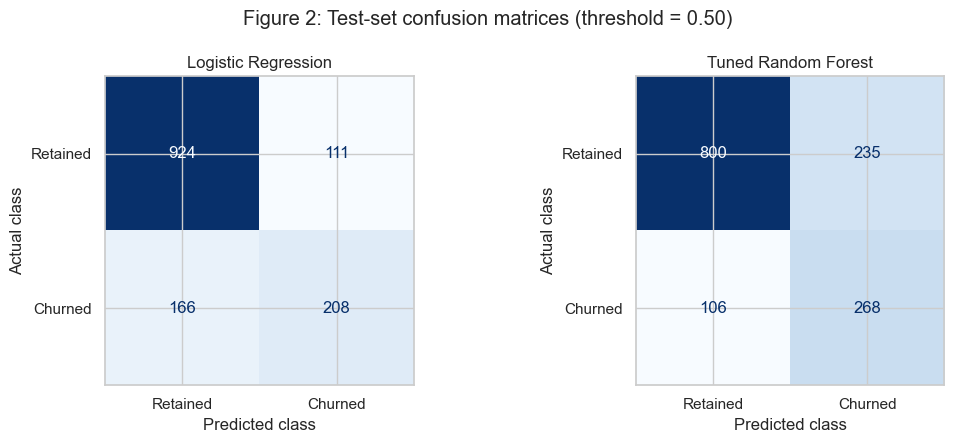

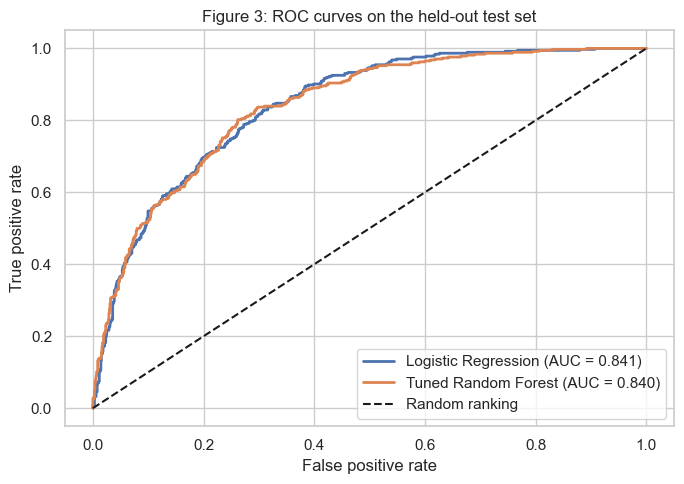

In [11]:
# Figure 2: Confusion matrices for both models
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, model_name in zip(axes, models):
    cm = confusion_matrix(y_test, predictions[model_name], labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=["Retained", "Churned"]
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(model_name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

fig.suptitle("Figure 2: Test-set confusion matrices (threshold = 0.50)")
plt.tight_layout()
plt.show()

# Figure 3: ROC curve comparison
plt.figure(figsize=(7, 5))
for model_name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_value = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, linewidth=2, label=f"{model_name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random ranking")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Figure 3: ROC curves on the held-out test set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Figure 2.** The confusion matrices show the number of correct and incorrect predictions for each class. False negatives represent churn cases not identified by the model; false positives represent customers incorrectly classified as churners. The ROC curves compare ranking performance across thresholds and do not determine an optimal operating threshold.


## 8. Permutation feature importance

Permutation importance is calculated for the fitted Random Forest using the held-out test data. Each input feature is shuffled in turn, and the resulting change in ROC-AUC is measured. A larger decrease indicates greater model reliance on that feature for this test sample. Permutation importance evaluates a feature by measuring the change in model performance after randomly shuffling its values ([Scikit-learn developers, n.d.-c](#ref-sklearn-perm)).

The measure describes predictive reliance rather than causation. Correlated variables may share or obscure importance; the ranking should not be interpreted as evidence that a feature causes churn.


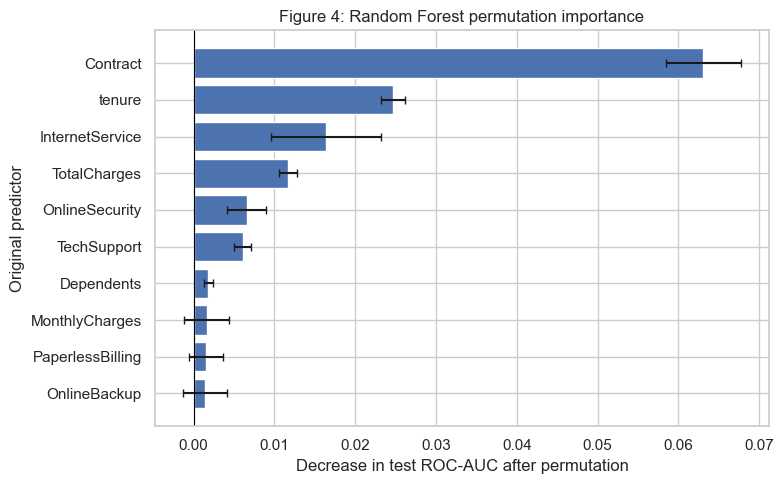

,Feature,Mean AUC decrease,Standard deviation
14,Contract,0.0631,0.0047
4,tenure,0.0247,0.0015
7,InternetService,0.0164,0.0068
18,TotalCharges,0.0117,0.0011
8,OnlineSecurity,0.0066,0.0024
11,TechSupport,0.0061,0.0011
3,Dependents,0.0018,0.0006
17,MonthlyCharges,0.0016,0.0028
15,PaperlessBilling,0.0015,0.0021
9,OnlineBackup,0.0014,0.0027


In [12]:
# Figure 4: Permutation importance at the original-feature level
best_rf_model = rf_search.best_estimator_

perm = permutation_importance(
    best_rf_model, X_test, y_test, scoring="roc_auc",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)

importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean AUC decrease": perm.importances_mean,
    "Standard deviation": perm.importances_std
}).sort_values("Mean AUC decrease", ascending=False)

top_importance = importance.head(10).sort_values("Mean AUC decrease")

plt.figure(figsize=(8, 5))
plt.barh(
    top_importance["Feature"], top_importance["Mean AUC decrease"],
    xerr=top_importance["Standard deviation"], capsize=3
)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Decrease in test ROC-AUC after permutation")
plt.ylabel("Original predictor")
plt.title("Figure 4: Random Forest permutation importance")
plt.tight_layout()
plt.show()

display(importance.head(10).round(4))

## 9. Classification threshold analysis

The default threshold of 0.5 is not necessarily appropriate for a retention application. Reducing the threshold generally increases the number of positive predictions and may increase recall and false positives. Increasing the threshold generally reduces positive predictions and may reduce recall.

The table compares precision and recall for the tuned Random Forest at selected thresholds. The dataset does not include intervention costs, customer lifetime value or treatment effectiveness; consequently, the most profitable threshold cannot be established from these results alone.


In [13]:
# 9.1 Threshold sensitivity for the tuned Random Forest
rf_test_prob = probabilities["Tuned Random Forest"]
threshold_rows = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    threshold_pred = (rf_test_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, threshold_pred, labels=[0, 1]).ravel()

    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, threshold_pred, zero_division=0),
        "Recall": recall_score(y_test, threshold_pred, zero_division=0),
        "F1": f1_score(y_test, threshold_pred, zero_division=0),
        "False positives": fp,
        "False negatives": fn,
        "Customers flagged": int(threshold_pred.sum())
    })

threshold_results = pd.DataFrame(threshold_rows).set_index("Threshold")
display(threshold_results.round(3))

,Precision,Recall,F1,False positives,False negatives,Customers flagged
Threshold,,,,,,
0.3,0.454,0.872,0.597,392,48,718
0.4,0.509,0.818,0.628,295,68,601
0.5,0.533,0.717,0.611,235,106,503
0.6,0.575,0.626,0.599,173,140,407
0.7,0.680,0.505,0.580,89,185,278


**Commercial implications.** Predicted churn probabilities could be used to prioritise customers for further assessment or retention activity. Threshold selection requires estimates of contact costs, customer value and intervention effectiveness. Predictions alone do not demonstrate that an intervention will prevent churn. Any operational use would also require privacy and fairness assessment, performance monitoring and periodic validation.


## 10. Conclusion and limitations

This study investigated the application of supervised machine learning to customer-churn prediction using the Telco Customer Churn dataset. Logistic Regression and Random Forest were implemented and evaluated using a stratified hold-out test set. Data preprocessing was incorporated into machine learning pipelines to minimise data leakage, while hyperparameter optimisation was conducted using stratified three-fold cross-validation on the training data.

The evaluation results indicate that both models demonstrated a comparable ability to distinguish between customers who churned and those who remained. Logistic Regression achieved a ROC-AUC of 0.8416, compared with 0.8407 for the tuned Random Forest. Although the difference was marginal, Logistic Regression achieved slightly stronger overall discrimination on the test set. The results therefore do not demonstrate a meaningful performance advantage for the tuned Random Forest.

The confusion matrices provide further insight into the classification errors made by each model, particularly false negatives, where customers who subsequently churned were incorrectly classified as non-churners. This is an important consideration in a commercial setting, as failing to identify customers at risk of leaving may reduce opportunities for targeted retention activity. Precision and recall should therefore be considered alongside accuracy when assessing the practical suitability of each model.

The ROC curves demonstrate that both classifiers provide useful discrimination beyond random classification. In addition, permutation feature importance provides an indication of which customer attributes contribute most to Random Forest predictive performance. These findings can help inform further investigation into customer behaviour, although feature importance should not be interpreted as evidence of causation.

Threshold analysis also demonstrates that classification performance depends on the selected probability threshold. Reducing the threshold can increase the identification of potential churners, but may also increase false-positive predictions. Consequently, the appropriate threshold depends on the organisation's retention budget, the cost of contacting customers and the financial impact of customer loss.

Several limitations should be acknowledged. The analysis uses data from a single telecommunications provider, which may limit the generalisability of the findings to other organisations. Model performance was assessed using one stratified hold-out test set, and further validation using additional datasets or repeated evaluation would provide stronger evidence of reliability. Furthermore, the dataset does not contain information about retention campaign costs or customer lifetime value. These factors would be necessary to determine whether the predictions generate measurable commercial benefits.

Overall, the findings demonstrate that Logistic Regression and Random Forest can provide useful approaches to customer-churn classification. Logistic Regression achieved the marginally higher ROC-AUC in this evaluation, while the Random Forest analysis provided additional insight into feature importance. Future work should investigate alternative classification algorithms, cost-sensitive threshold selection and validation on additional customer datasets. Incorporating customer lifetime value and retention costs would also allow predictive performance to be evaluated in terms of business profitability rather than classification metrics alone.

## Limitations

Several limitations should be considered when interpreting the results of this study.

**Dataset limitations:** The analysis uses customer data from a single telecommunications provider. Consequently, the findings may not generalise to organisations with different customer demographics, services or pricing structures. The dataset also represents a particular period, meaning changes in customer behaviour over time may not be reflected.

**Model evaluation:** Performance was assessed using a single stratified 80:20 train-test split. Although cross-validation was used for hyperparameter selection, evaluating the final models on additional independent datasets or through repeated train-test splits would provide stronger evidence of generalisability.

**Class imbalance:** The dataset contains fewer customers who churned than customers who remained. Although stratified sampling and class weighting were applied, classification performance may still be affected by the unequal distribution of the target classes. Accuracy alone is therefore insufficient to assess model effectiveness.

**Feature limitations:** The dataset contains a restricted set of customer and account characteristics. Factors such as customer satisfaction, competitor pricing, service quality and reasons for cancellation are not fully represented. Their absence may limit the models' ability to identify the underlying factors associated with churn.

**Business applicability:** The models generate churn predictions but do not establish whether a retention intervention would prevent a customer from leaving. Information about customer lifetime value, retention campaign costs and intervention success rates would be required to assess the financial value of the predictions.

**Model interpretability:** Logistic Regression provides a relatively straightforward classification approach, whereas Random Forest combines multiple decision trees and is more difficult to interpret. Permutation feature importance indicates the contribution of individual features to predictive performance but does not establish causal relationships between customer characteristics and churn.

These limitations suggest that the results should be interpreted as an evaluation of predictive performance on the available dataset rather than evidence that either model would achieve the same performance in a live telecommunications environment.


## Use of generative AI

This appendix records generative AI assistance in accordance with the assessment brief.

### Tools

- Gemini.
- ChatGPT.

### Development and verification

Generative AI was used for assistance with notebook structure, explanations and code development. Suggestions were reviewed and adapted before inclusion.

**Examples of prompts used during development:**
- "How should I structure a machine-learning notebook for predicting customer churn using Logistic Regression and a tuned Random Forest?"
- "How can imputation, one-hot encoding and scaling be implemented within a scikit-learn Pipeline and ColumnTransformer to reduce data leakage?"
- "How should precision, recall, F1-score and ROC-AUC be interpreted for an imbalanced churn target?"
- "How can permutation importance be calculated for a fitted scikit-learn pipeline using the original input features?"
- "How should false-positive, false-negative and classification-threshold results be interpreted in a customer-retention context?"

## References

<div id="ref-ibm"></div>
Kaggle (n.d.) *Telco Customer Churn*. Available at: https://www.kaggle.com/datasets/blastchar/telco-customer-churn (Accessed: 14 October 2026).

<div id="ref-sklearn-guide"></div>
Scikit-learn developers (n.d.-a) Classification metrics. Available at: https://scikit-learn.org/stable/modules/model_evaluation.html (Accessed: 2 November 2026).

<div id="ref-sklearn-pipeline"></div>
Scikit-learn developers (n.d.-b) Pipelines and composite estimators. Available at: https://scikit-learn.org/stable/modules/compose.html (Accessed: 2 November 2026).

<div id="ref-sklearn-perm"></div>
Scikit-learn developers (n.d.-c) Permutation feature importance. Available at: https://scikit-learn.org/stable/modules/permutation_importance.html (Accessed: 2 November 2026).

<div id="ref-sklearn-logistic"></div>
Scikit-learn developers (n.d.-d) Logistic regression. Available at: https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression (Accessed: 2 November 2026).

<div id="ref-sklearn-forest"></div>
Scikit-learn developers (n.d.-e) Random forests. Available at: https://scikit-learn.org/stable/modules/ensemble.html#random-forests (Accessed: 2 November 2026).
